**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [12]:
versioni = dh.get_artifact_versions("moco_2D_metrics_net_v5", project="floods")
for v in sorted(versioni, key=lambda v: v.metadata.created):
    print(v.id, v.metadata.created)

fecf7148756c464e807dd3b6bca5db75 2026-10-26T15:40:51.646Z
124199cc3e54463282baecd5a7299e28 2026-10-26T15:40:58.883Z
4d1f5bfeefca433cb6bceee7dcd50d5d 2026-10-26T15:41:06.081Z
2f0a1a73799b4b44aa5f72053370f7b4 2026-10-26T16:39:47.287Z
f8becd3c5b5e433e8fb2864bc778f330 2026-10-26T17:02:43.681Z
bd525ad7d09e45b8a34a56fdad8a92d5 2026-10-26T17:22:49.423Z
2c14c0449d2c4f34bfd09afd1cf1bd85 2026-10-26T17:42:59.87Z
3c6d0ee7c67d47cf96d62ba5926f4893 2026-10-26T18:03:09.301Z
a0287c5ac07a4aa0b107ee06906f1c13 2026-10-26T18:23:18.721Z
64c00adefac2444c9a1b45d90020db77 2026-10-26T18:43:35.191Z
bb68e2152734447bb3118726b1d480fd 2026-10-26T19:03:46.654Z
d47aeb4ef4b04c4098f86c9a9101b493 2026-10-26T19:23:57.919Z
43e9e08b2f9b4acba5bfce791c3d3073 2026-10-26T19:44:12.01Z
62927cee1a544756a391a1a0ef76d358 2026-10-26T20:04:26.254Z
b14bbd54b9ef4219b5a99a7a7e1e0469 2026-10-26T20:26:04.968Z
50f93483cd584c9a98a6dac15446231e 2026-10-26T20:46:44.686Z
70a1b1490495441bb9fb0e8784398097 2026-10-26T21:07:23.132Z
b6645a136d6c4684

In [13]:
versioni = dh.get_artifact_versions("moco_2D_weights_net_v5", project="floods")
for v in sorted(versioni, key=lambda v: v.metadata.created):
    print(v.id, v.metadata.created)

e17bfd61a70e47a5af530fe441cbf570 2026-10-26T15:40:53.061Z
9b272602720242d9ab0bc1a6d5c57b25 2026-10-26T15:41:00.306Z
88ce11eb0ff24a3da3e90cb280a0c976 2026-10-26T16:39:48.879Z
cc701bb74f42455ebbbcf9d45b56872c 2026-10-26T17:02:45.098Z
accaab6a8f6a4be49e95db801030caf6 2026-10-26T17:22:50.861Z
9be8c58108524d37868fa26197a9a9d2 2026-10-26T17:43:01.717Z
7472d641b4b44792a90d92f2fa84377f 2026-10-26T18:03:10.809Z
1db6080006f04953bcbdb66fbc863d9d 2026-10-26T18:23:20.254Z
2095783603e844b890490aa8160a38fd 2026-10-26T18:43:36.626Z
c154a2b2275d4495a8cba473f893510e 2026-10-26T19:23:59.796Z
5236faf54a104a03b4148443fcdbc736 2026-10-26T19:44:13.699Z
8bf5f7e62602485ab3a58ae606ed968f 2026-10-26T20:26:06.722Z
9ccf57b762264d468e2a6fd400e21fb9 2026-10-26T21:07:24.468Z
2a3758c4658a49cda22a8e36af3f6d6b 2026-10-26T22:09:09.036Z
9c23c3ba8e8242d085097848abb63250 2026-10-26T22:50:26.234Z
6a0eccc320284a7084d28f5341541516 2026-10-27T00:33:22.746Z
9baf5e5af0694bd5b9bc2013a8b32be2 2026-10-27T00:53:58.228Z
0ca782a60e3849

**SETUP PARAMETERS**

In [2]:
job_name = "net_v5_ep20_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v5"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False,  
    "weights_version": "9baf5e5af0694bd5b9bc2013a8b32be2",              
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                       # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,

    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                      # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [6]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all3',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm3",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [7]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-06 09:28:18,404 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...


2026-11-06 09:28:23,411 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:28,420 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:33,428 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:38,437 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:43,445 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:48,454 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09:28:53,462 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cd8758e75d9b4dafa8b2fe7c303aed74 to finish...
2026-11-06 09

Run anomaly detection ocsvm: cd8758e75d9b4dafa8b2fe7c303aed74


In [3]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           # una cartella per job
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              # solo i punti calcolati in questa run
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          # punto -> (results, df), per i grafici
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

# confronto tra i punti
print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: net_v5_ep20_0per | moco: net_v5 | punti: encoder, pre_proj, proj_raw, post_proj 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.026395735922747583
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.049
min_flood_area = 0.000
score normali: 19.3486 ± 14.9463
score anomale: 3.9522 ± 13.0074
AUROC: 0.779


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-7.882406,616.0,84.0,1786.0,2318.0,0.034971,0.743547,0.256453,0.880000,0.397163
FA 10%,-4.075033,939.0,213.0,1463.0,2189.0,0.088676,0.609076,0.390924,0.815104,0.528419
FA 15%,-0.010772,1159.0,328.0,1243.0,2074.0,0.136553,0.517485,0.482515,0.779422,0.596040
FA 20%,3.211639,1325.0,440.0,1077.0,1962.0,0.183181,0.448376,0.551624,0.750708,0.635949
FA 25%,6.749429,1502.0,558.0,900.0,1844.0,0.232306,0.374688,0.625312,0.729126,0.673241
FA 30%,9.656719,1636.0,677.0,766.0,1725.0,0.281848,0.318901,0.681099,0.707307,0.693955


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.03098242243825635
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.052
min_flood_area = 0.000
score normali: 9.2045 ± 5.1038
score anomale: 4.7224 ± 5.0827
AUROC: 0.734


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-0.915704,420.0,94.0,1982.0,2308.0,0.039134,0.825146,0.174854,0.817121,0.288066
FA 10%,0.319339,659.0,186.0,1743.0,2216.0,0.077435,0.725645,0.274355,0.779882,0.405913
FA 15%,2.012329,894.0,314.0,1508.0,2088.0,0.130724,0.627810,0.372190,0.740066,0.495291
FA 20%,3.673888,1123.0,438.0,1279.0,1964.0,0.182348,0.532473,0.467527,0.719411,0.566742
FA 25%,5.050464,1328.0,547.0,1074.0,1855.0,0.227727,0.447127,0.552873,0.708267,0.620996
FA 30%,6.494201,1483.0,676.0,919.0,1726.0,0.281432,0.382598,0.617402,0.686892,0.650296


===== post_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.0022785222352486945
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 25.4572 ± 16.2343
score anomale: 9.8639 ± 14.4121
AUROC: 0.761


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-3.377516,455.0,101.0,1947.0,2301.0,0.042048,0.810575,0.189425,0.818345,0.307640
FA 10%,2.007367,738.0,181.0,1664.0,2221.0,0.075354,0.692756,0.307244,0.803047,0.444444
FA 15%,6.432029,1015.0,309.0,1387.0,2093.0,0.128643,0.577435,0.422565,0.766616,0.544820
FA 20%,9.831361,1236.0,408.0,1166.0,1994.0,0.169858,0.485429,0.514571,0.751825,0.610974
FA 25%,12.920831,1411.0,535.0,991.0,1867.0,0.222731,0.412573,0.587427,0.725077,0.649034
FA 30%,15.992920,1601.0,700.0,801.0,1702.0,0.291424,0.333472,0.666528,0.695784,0.680842


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.026,0.779
proj_raw,256,0.031,0.734
post_proj,256,0.002,0.761


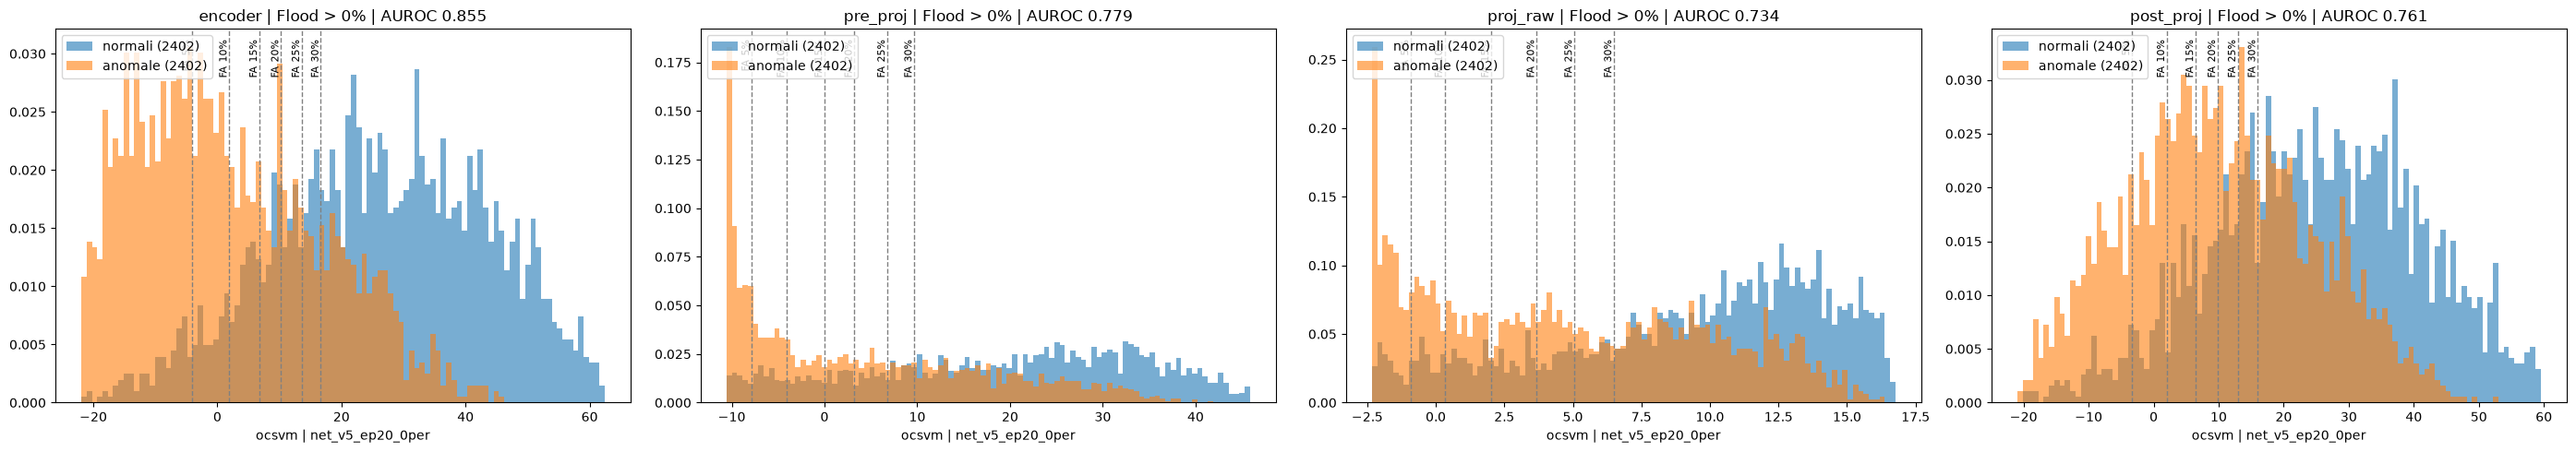

In [9]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

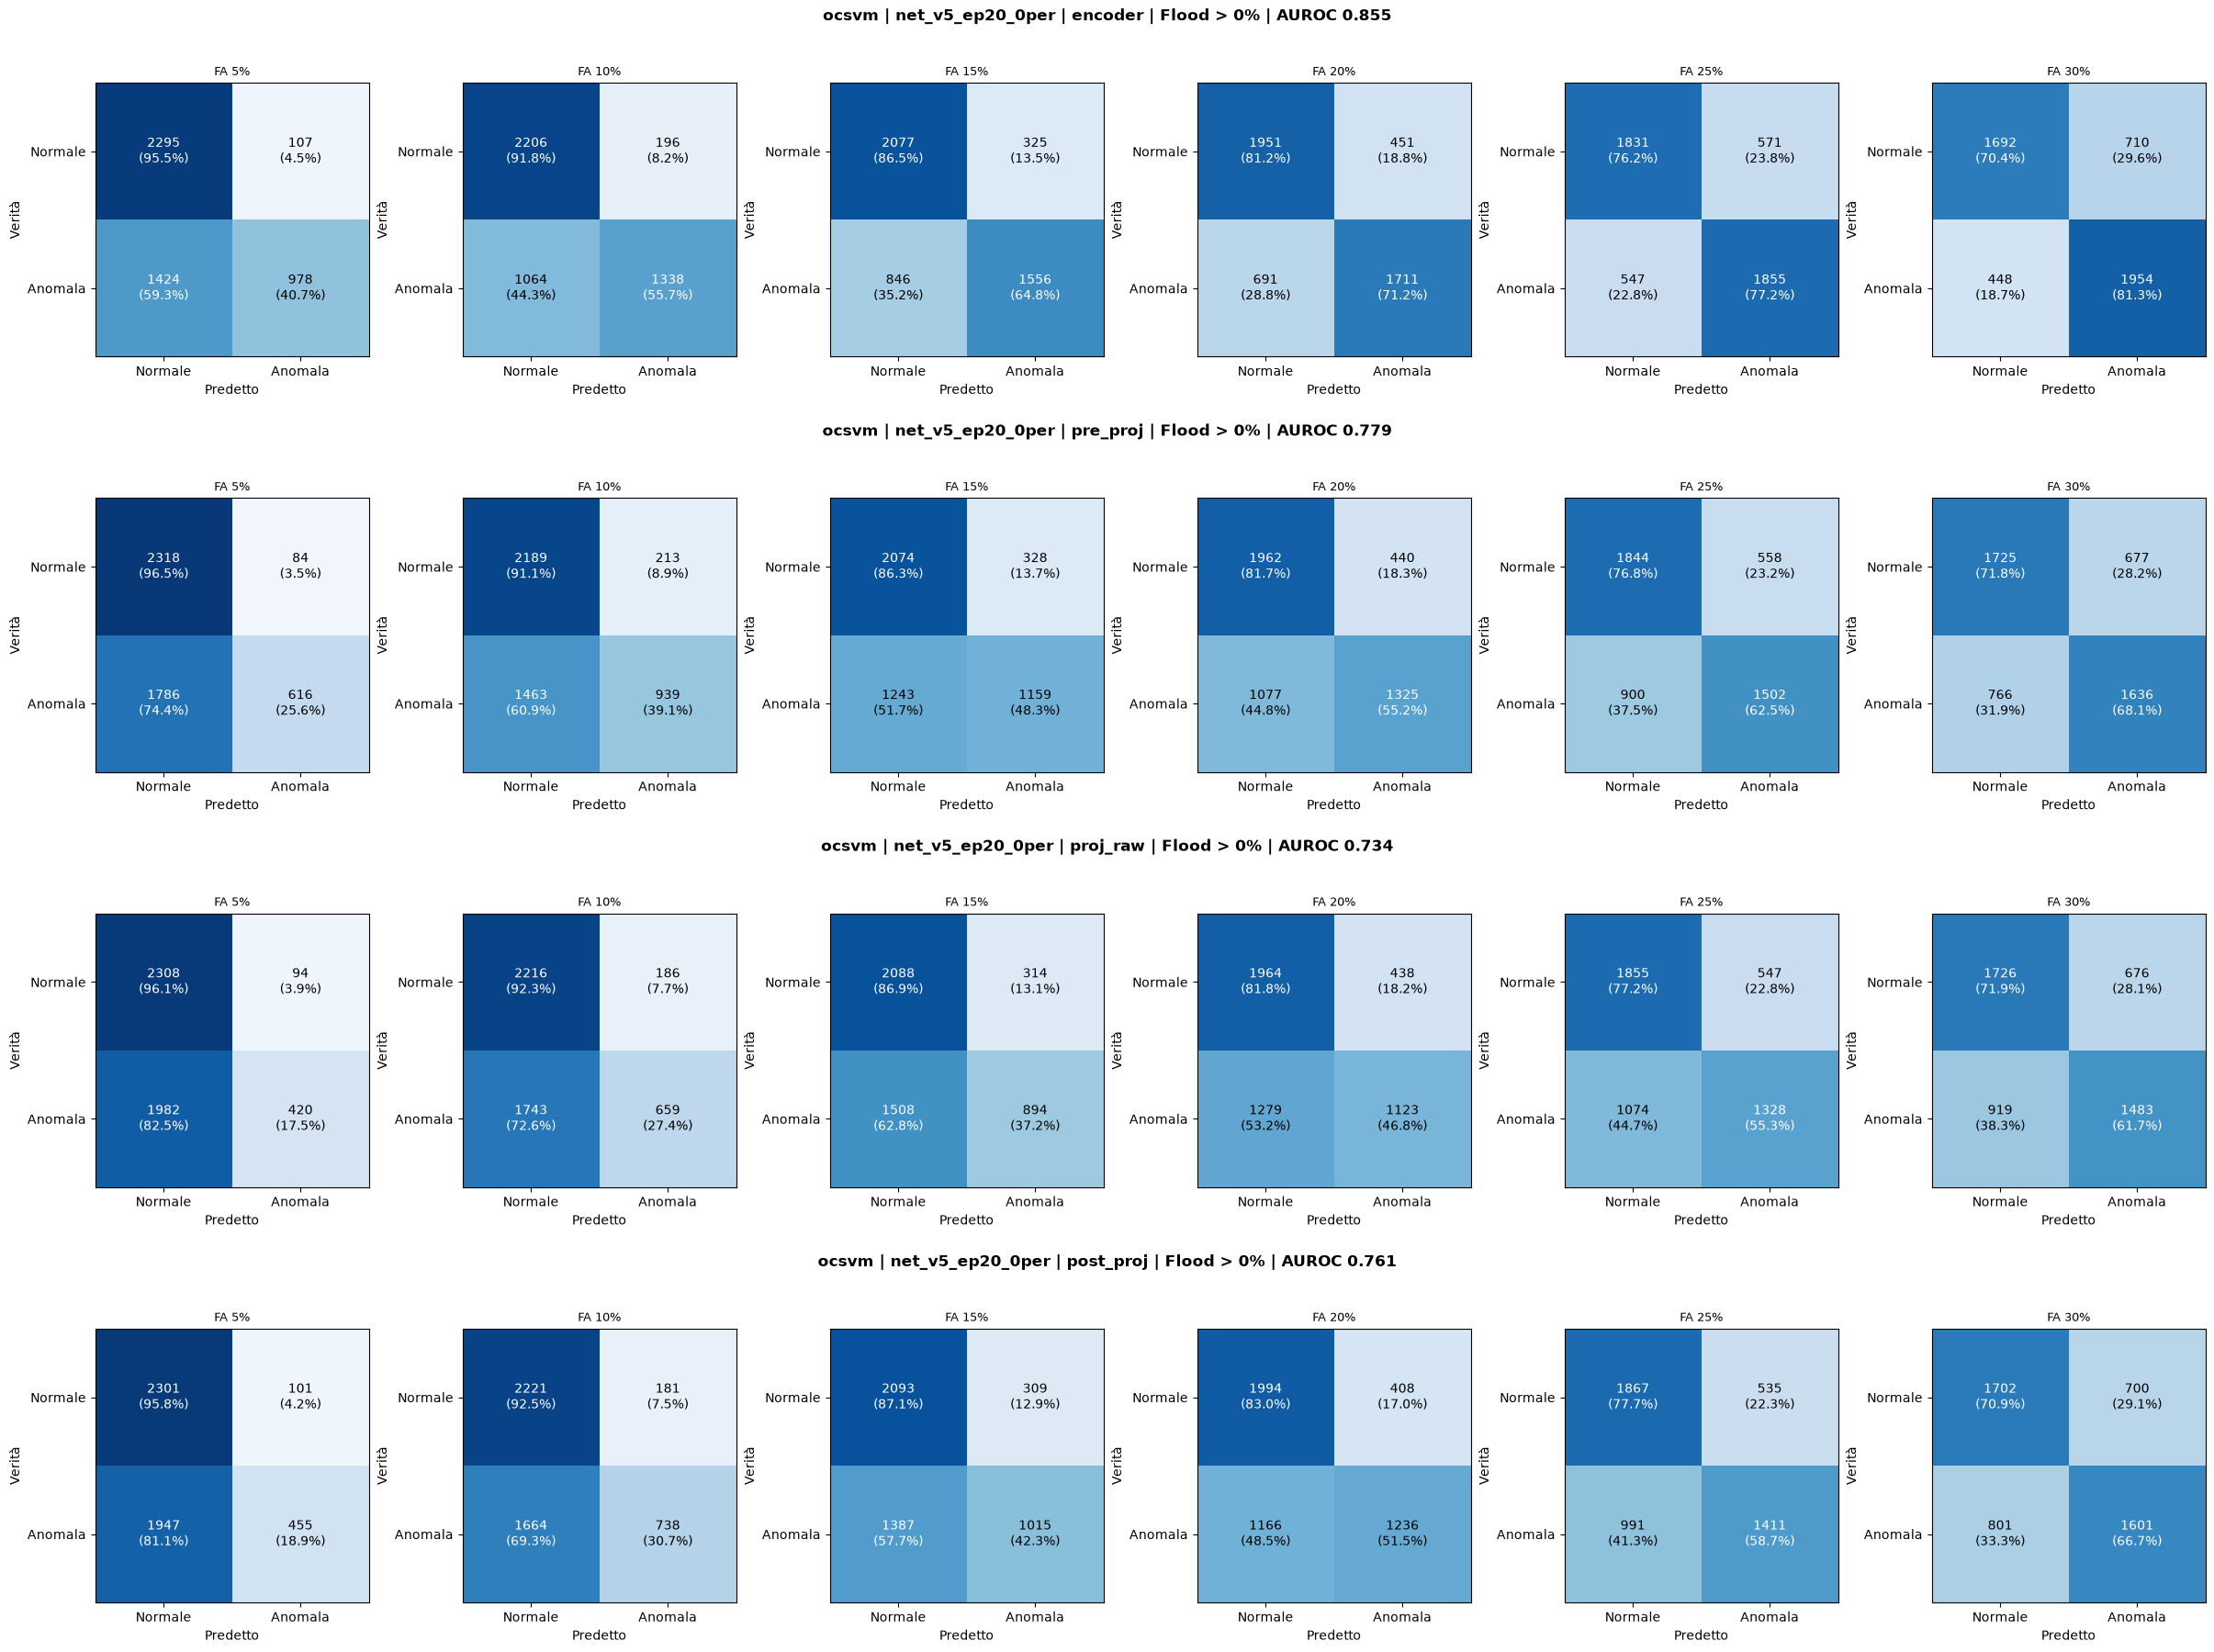

In [10]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [4]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                    
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}          
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC validazione": auroc(md, n_val, a_val),                
    })

lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC validazione": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_net_v5_ep20_0per
job:           net_v5_ep20_0per | moco: net_v5 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.779 (ocsvm, whitening lw, 4096 componenti) 

forme: {'fit': (19893, 4096), 'thr': (2572, 4096), 'normal': (2402, 4096), 'anom': (2402, 4096)} 

Ledoit-Wolf shrinkage: 0.026
           thr/fit  AUROC validazione
k                                    
32           1.117              0.669
64           1.078              0.676
128          1.055              0.697
256          1.035              0.717
512          1.027              0.731
768          1.029              0.740
1024         1.038              0.744
1536         1.070              0.749
2048         1.119              0.755
3072         1.267              0.767
4096    

In [ ]:
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

def carica(results_dir, punto):
    E = np.load(f"{results_dir}/{punto}/embeddings.npz")
    return {g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)
            for g in ("fit", "normal", "anom")}

enc = carica(RESULTS_DIR, "encoder")
pre = carica(RESULTS_DIR, "pre_proj")
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]

def md_lw(w):
    sc = StandardScaler().fit(w["fit"])
    w = {g: sc.transform(v) for g, v in w.items()}
    lw = LedoitWolf().fit(w["fit"])
    return {g: lw.mahalanobis(v) for g, v in w.items()}

s_enc = md_lw(enc)
s_pre = md_lw(pre)
s_cat = md_lw({g: np.concatenate([enc[g], pre[g]], axis=1) for g in enc})

from scipy.stats import rankdata
r = lambda s: rankdata(np.r_[s["normal"], s["anom"]]) / (len(s["normal"]) + len(s["anom"]))
s_fus = (r(s_enc) + r(s_pre)) / 2

for nome, s in (("encoder", np.r_[s_enc["normal"], s_enc["anom"]]),
                ("pre_proj", np.r_[s_pre["normal"], s_pre["anom"]]),
                ("encoder + pre_proj (concatenati)", np.r_[s_cat["normal"], s_cat["anom"]]),
                ("encoder + pre_proj (media dei ranghi)", s_fus)):
    print(f"{nome:38s}: AUROC {roc_auc_score(y, s):.3f}")

In [ ]:
from scipy.stats import spearmanr

tutti_enc = np.r_[s_enc["normal"], s_enc["anom"]]
tutti_pre = np.r_[s_pre["normal"], s_pre["anom"]]
print(f"correlazione di Spearman tra gli score: {spearmanr(tutti_enc, tutti_pre).correlation:.3f}")

correlazione di Spearman tra gli score: 0.775


In [ ]:
from scipy.stats import spearmanr

fa = 0.10                                                   

enc = carica(RESULTS_DIR, "encoder")
s_enc = md_lw(enc)
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]
tutti = lambda s: np.r_[s["normal"], s["anom"]]

def rilevate(s):
    soglia = np.quantile(s["normal"], 1 - fa)
    return s["anom"] > soglia

righe = []
for punto in ("pre_proj", "proj_raw", "post_proj"):
    print(f"--- {punto} ---", flush=True)
    altro = carica(RESULTS_DIR, punto)
    s_alt = md_lw(altro)
    s_cat = md_lw({g: np.concatenate([enc[g], altro[g]], axis=1) for g in enc})

    r_enc, r_alt = rilevate(s_enc), rilevate(s_alt)
    righe.append({
        "punto": punto,
        "AUROC punto": roc_auc_score(y, tutti(s_alt)),
        "concatenati": roc_auc_score(y, tutti(s_cat)),
        "media ranghi": roc_auc_score(y, (r(s_enc) + r(s_alt)) / 2),
        "massimo ranghi": roc_auc_score(y, np.maximum(r(s_enc), r(s_alt))),
        "Spearman": spearmanr(tutti(s_enc), tutti(s_alt)).correlation,
        "solo encoder": np.mean(r_enc & ~r_alt),
        "solo punto": np.mean(~r_enc & r_alt),
    })

print(f"\nencoder da solo: AUROC {roc_auc_score(y, tutti(s_enc)):.3f}")
pd.DataFrame(righe).set_index("punto").round(3)

--- pre_proj ---
--- proj_raw ---
--- post_proj ---

encoder da solo: AUROC 0.855


,AUROC punto,concatenati,media ranghi,massimo ranghi,Spearman,solo encoder,solo punto
punto,,,,,,,
pre_proj,0.803,0.814,0.851,0.838,0.775,0.206,0.047
proj_raw,0.750,0.855,0.835,0.813,0.637,0.328,0.050
post_proj,0.630,0.855,0.789,0.770,0.408,0.411,0.044
